In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [2]:
df = pd.read_csv("../../datasets/heart_final_cleaned.csv")
df = df.dropna()

X = df.drop("target", axis=1).values
y = df["target"].values.reshape(-1, 1)

print("Dataset Shape:", df.shape)

Dataset Shape: (302, 14)


In [3]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42, stratify=y_train
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)

print("Training Shape:", X_train.shape)
print("Validation Shape:", X_val.shape)

Training Shape: (192, 13)
Validation Shape: (49, 13)


In [4]:
np.random.seed(42)

input_size = X_train.shape[1]
hidden_size = 16
output_size = 1

W1 = np.random.randn(input_size, hidden_size) * 0.01
b1 = np.zeros((1, hidden_size))

W2 = np.random.randn(hidden_size, output_size) * 0.01
b2 = np.zeros((1, output_size))

def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

def forward_pass(X):
    Z1 = X @ W1 + b1
    A1 = np.maximum(0, Z1)

    Z2 = A1 @ W2 + b2
    A2 = sigmoid(Z2)

    return Z1, A1, A2

In [5]:
def binary_cross_entropy(y_true, y_pred):
    epsilon = 1e-8

    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)

    loss = -np.mean(
        y_true * np.log(y_pred) +
        (1 - y_true) * np.log(1 - y_pred)
    )

    return loss

In [6]:
learning_rate = 0.01
epochs = 300

train_losses = []
validation_losses = []

for epoch in range(epochs):

    # Training forward pass
    Z1, A1, A2 = forward_pass(X_train)

    train_loss = binary_cross_entropy(y_train, A2)

    # Backpropagation
    m = len(X_train)

    dZ2 = A2 - y_train
    dW2 = (A1.T @ dZ2) / m
    db2 = np.mean(dZ2, axis=0, keepdims=True)

    dA1 = dZ2 @ W2.T
    dZ1 = dA1 * (Z1 > 0)

    dW1 = (X_train.T @ dZ1) / m
    db1 = np.mean(dZ1, axis=0, keepdims=True)

    # Update parameters
    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2

    # Calculate training loss after update
    _, _, train_predictions = forward_pass(X_train)
    train_loss = binary_cross_entropy(y_train, train_predictions)

    # Calculate validation loss
    _, _, val_predictions = forward_pass(X_val)
    val_loss = binary_cross_entropy(y_val, val_predictions)

    train_losses.append(train_loss)
    validation_losses.append(val_loss)

    if (epoch + 1) % 50 == 0:
        print(
            f"Epoch {epoch + 1}: "
            f"Training Loss = {train_loss:.4f}, "
            f"Validation Loss = {val_loss:.4f}"
        )

Epoch 50: Training Loss = 0.6922, Validation Loss = 0.6920
Epoch 100: Training Loss = 0.6914, Validation Loss = 0.6911
Epoch 150: Training Loss = 0.6907, Validation Loss = 0.6902
Epoch 200: Training Loss = 0.6900, Validation Loss = 0.6894
Epoch 250: Training Loss = 0.6892, Validation Loss = 0.6887
Epoch 300: Training Loss = 0.6884, Validation Loss = 0.6879


In [7]:
loss_df = pd.DataFrame({
    "Epoch": range(1, epochs + 1),
    "Training Loss": train_losses,
    "Validation Loss": validation_losses
})

display(loss_df.head(10))

,Epoch,Training Loss,Validation Loss
0,1,0.693172,0.693145
1,2,0.693151,0.693120
2,3,0.693130,0.693095
3,4,0.693109,0.693071
4,5,0.693088,0.693046
5,6,0.693067,0.693022
6,7,0.693046,0.692997
7,8,0.693025,0.692973
8,9,0.693004,0.692948
9,10,0.692983,0.692924


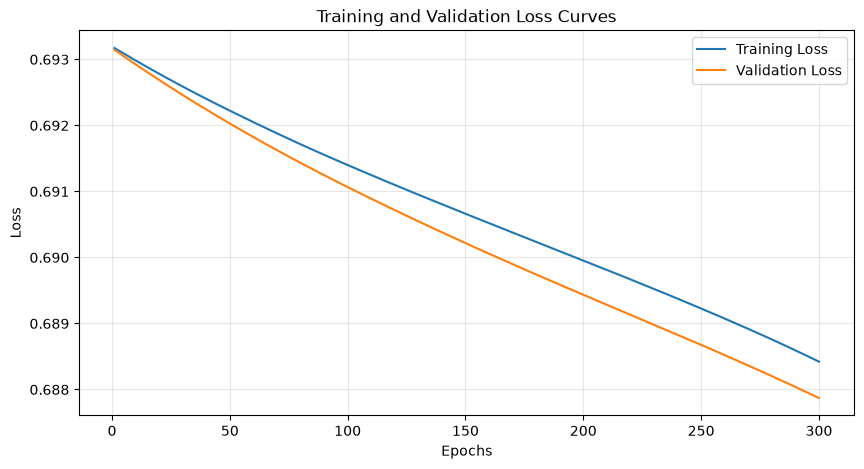

In [8]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, epochs + 1),
    train_losses,
    label="Training Loss"
)

plt.plot(
    range(1, epochs + 1),
    validation_losses,
    label="Validation Loss"
)

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training and Validation Loss Curves")

plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [9]:
initial_train_loss = train_losses[0]
final_train_loss = train_losses[-1]

initial_val_loss = validation_losses[0]
final_val_loss = validation_losses[-1]

print("Initial Training Loss:", round(initial_train_loss, 4))
print("Final Training Loss:", round(final_train_loss, 4))

print("Initial Validation Loss:", round(initial_val_loss, 4))
print("Final Validation Loss:", round(final_val_loss, 4))

if final_train_loss < initial_train_loss:
    print("Training loss decreased: Model learned from training data.")

if final_val_loss < initial_val_loss:
    print("Validation loss decreased: Model improved on unseen validation data.")
else:
    print("Validation loss did not decrease overall.")

Initial Training Loss: 0.6932
Final Training Loss: 0.6884
Initial Validation Loss: 0.6931
Final Validation Loss: 0.6879
Training loss decreased: Model learned from training data.
Validation loss decreased: Model improved on unseen validation data.


In [10]:
print("""
Conclusion:

Training loss measures how well the model performs on training data.

Validation loss measures how well the model generalizes to unseen data.

When both losses decrease, the model is learning effectively.

If training loss decreases but validation loss starts increasing,
it may indicate overfitting.

Loss curves help understand model learning behavior and identify
possible overfitting or underfitting.
""")


Conclusion:

Training loss measures how well the model performs on training data.

Validation loss measures how well the model generalizes to unseen data.

When both losses decrease, the model is learning effectively.

If training loss decreases but validation loss starts increasing,
it may indicate overfitting.

Loss curves help understand model learning behavior and identify
possible overfitting or underfitting.

